# Instrumental variables, GMM and the score bootstrap

Linear IV is an optimization problem with moment conditions
$$m(b)=Z^T(Xb-y)/n,\qquad Q(b)=\tfrac12m(b)^TWm(b).$$
Its gradient is $D^TWm$ and its Hessian is $D^TWD$, where $D=Z^TX/n$.
The default weight $(Z^TZ/n)^{-1}$ yields 2SLS. This notebook compares point
estimates, makes a two-step weight update explicitly, checks robust uncertainty
using bootstrap draws, and supplies a nonlinear logit moment criterion directly.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1006)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from scipy.special import expit
from scipy.stats import norm
from galahad_econometrics import OLS, IVGMM, Logit, Criterion, tru, arc, check_derivatives

n = 2000
Z_features = rng.normal(size=(n, 3))
epsilon = rng.normal(size=n)
v = .7*epsilon + .7*rng.normal(size=n)
x = .8*Z_features[:, 0] + .4*Z_features[:, 1] + v
sigma = .3 + .35*np.abs(Z_features[:, 0])
u = sigma*epsilon
beta = np.array([.5, 1.2])
y = beta[0] + beta[1]*x + u
X_features = x[:, None]
D = np.column_stack([np.ones(n), X_features])
Z = np.column_stack([np.ones(n), Z_features])

## Default 2SLS and an explicit second step

The endogenous regressor contains a component correlated with the structural
error. Instrument validity follows from the independent, mean-zero innovation,
conditional on the instruments. The two-step weight below uses first-step
residuals. It remains fixed during the second optimization, exactly as specified
by the fixed-weight `IVGMM` interface.

In [3]:
ols = OLS(X_features, y).fit(cov_type="HC1")
model = IVGMM(X_features, y, Z_features)
first = model.fit(solver="tru", cov_type="HC1")
first_arc = model.fit(solver="arc", cov_type="HC1")
residual = D @ first.params - y
moment_rows = Z * residual[:, None]
omega = moment_rows.T @ moment_rows / n
second_weight = np.linalg.inv(omega)
second = IVGMM(X_features, y, Z_features, weight=second_weight).fit(solver="arc", cov_type="HC1")

M = Z.T @ D / n
closed = np.linalg.solve(M.T @ model.weight @ M, M.T @ model.weight @ (Z.T @ y/n))
assert np.max(np.abs(first.params - closed)) < 1e-7
assert np.max(np.abs(first.params - first_arc.params)) < 1e-7
pd.DataFrame({"truth": beta, "OLS": ols.params, "2SLS TRU": first.params,
              "2SLS ARC": first_arc.params, "two-step GMM ARC": second.params},
             index=["intercept", "endogenous slope"])

,truth,OLS,2SLS TRU,2SLS ARC,two-step GMM ARC
intercept,0.5,0.49687,0.49408,0.49408,0.4931
endogenous slope,1.2,1.4239,1.1993,1.1993,1.1947


## Fast influence-function bootstrap

For an additive mean criterion with individual gradient rows $s_i$, the estimated
influence rows are $\varphi_i=-H^{-1}s_i$. Centering the rows removes the small
remaining sample gradient. A pairs-resampling linearization is
$$\hat b^*_{\mathrm{linear}}=\hat b+\frac1n\sum_j\hat\varphi_{I_j}.$$
The full bootstrap below refits exactly the same fixed-weight IV criterion on
resampled observations. Both bootstrap variants hold the original weight fixed;
they do not re-estimate the second-step weight. Draws are independent between
methods. The score approximation and full bootstrap need not coincide at finite $n$.

In [4]:
scores = model.scores(first.params)
H = model.hess(first.params)
influence = -np.linalg.solve(H, scores.T).T
influence -= influence.mean(axis=0)
B_fast, B_full = 1500, 100
fast_draws = np.empty((B_fast, 2))
for b in range(B_fast):
    ids = rng.integers(0, n, size=n)
    fast_draws[b] = first.params + influence[ids].mean(axis=0)

full_draws = np.empty((B_full, 2))
for b in range(B_full):
    ids = rng.integers(0, n, size=n)
    boot = IVGMM(X_features[ids], y[ids], Z_features[ids], weight=model.weight)
    full_draws[b] = boot.fit(solver="tru", x0=first.params).params

fast_se, full_se = fast_draws.std(axis=0, ddof=1), full_draws.std(axis=0, ddof=1)
assert np.isfinite(full_draws).all()
assert np.allclose(fast_se, first.bse, rtol=.15)
pd.DataFrame({"estimate": first.params, "HC1 SE": first.bse,
              "linearized bootstrap SE": fast_se, "full fixed-W bootstrap SE": full_se},
             index=["intercept", "endogenous slope"])

,estimate,HC1 SE,linearized bootstrap SE,full fixed-W bootstrap SE
intercept,0.49408,0.01364,0.013739,0.013031
endogenous slope,1.1993,0.020358,0.020228,0.018062


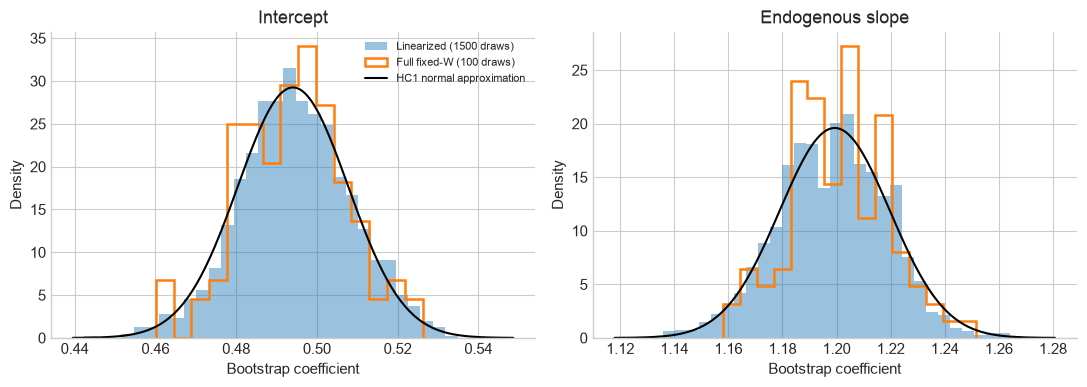

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for j, ax in enumerate(axes):
    ax.hist(fast_draws[:, j], bins=30, density=True, alpha=.45, label=f"Linearized ({B_fast} draws)")
    ax.hist(full_draws[:, j], bins=15, density=True, histtype="step", linewidth=1.8,
             label=f"Full fixed-W ({B_full} draws)")
    grid = np.linspace(first.params[j]-4*first.bse[j], first.params[j]+4*first.bse[j], 200)
    ax.plot(grid, norm.pdf(grid, first.params[j], first.bse[j]), color="black", label="HC1 normal approximation")
    ax.set(title=["Intercept", "Endogenous slope"][j], xlabel="Bootstrap coefficient", ylabel="Density")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Nonlinear GMM through a custom criterion

Logit score moments $m(b)=n^{-1}X^T[y-\Lambda(Xb)]$ are just identified when
$Z=X$. Solving them reproduces the logit MLE in this regular sample. The GMM
objective is nonlinear, even though the built-in `IVGMM` constructor is linear.
Its exact Hessian includes both $D^TWD$ and residual-moment curvature; the code
below supplies that term explicitly. No new library estimator or autodiff package
is required.

In [6]:
ng = 1400
Xg = np.column_stack([np.ones(ng), rng.normal(size=(ng, 2))])
truth_g = np.array([.3, -.6, .5])
yg = rng.binomial(1, expit(Xg @ truth_g))
Wg = np.linalg.inv(Xg.T @ Xg / ng)

def pieces(b):
    mu = expit(Xg @ b)
    w = mu*(1-mu)
    moment = Xg.T @ (yg-mu) / ng
    jac = -Xg.T @ (w[:, None]*Xg) / ng
    return mu, w, moment, jac

def gmm_fun(b):
    _, _, m, _ = pieces(b)
    return float(.5 * m @ Wg @ m)

def gmm_grad(b):
    _, _, m, J = pieces(b)
    return J.T @ Wg @ m

def gmm_hess(b):
    mu, w, m, J = pieces(b)
    weighted_curvature = (Xg @ (Wg @ m))*w*(1-2*mu)
    return J.T @ Wg @ J - Xg.T @ (weighted_curvature[:, None]*Xg) / ng

nonlinear = Criterion(gmm_fun, gmm_grad, gmm_hess)
assert max(check_derivatives(nonlinear, np.array([.1, -.2, .3])).values()) < 1e-6
mle = Logit(Xg, yg, intercept=False).fit()
gmm_tru = tru.solve(nonlinear, np.zeros(3))
gmm_arc = arc.solve(nonlinear, np.zeros(3))
assert gmm_tru.success and gmm_arc.success
assert np.max(np.abs(gmm_tru.x-mle.params)) < 2e-5
assert np.max(np.abs(gmm_arc.x-mle.params)) < 2e-5
pd.DataFrame({"truth": truth_g, "Logit MLE": mle.params, "GMM TRU": gmm_tru.x, "GMM ARC": gmm_arc.x},
             index=["intercept", "x1", "x2"])

,truth,Logit MLE,GMM TRU,GMM ARC
intercept,0.3,0.28401,0.28401,0.28401
x1,-0.6,-0.49559,-0.49559,-0.49559
x2,0.5,0.4287,0.4287,0.4287


The optimizer solves the supplied sample moment problem. It cannot establish
instrument validity, repair weak identification or supply weak-IV-robust
inference. The bootstrap comparison above is a demonstration for a regular,
identified DGP; it is not a coverage guarantee.